In [1]:
import numpy as np 
import pandas as pd 
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer

In [3]:
df = pd.read_csv('titanic_toy.csv')

In [4]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [20]:
df.isnull().sum()

Age         177
Fare         45
Family        0
Survived      0
dtype: int64

In [22]:
df.isnull().mean()

Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64

In [24]:
x_train,x_test,y_train,y_test = train_test_split(df.drop(columns=['Survived']),df.iloc[:,0:3],test_size=0.2,random_state=42)

In [25]:
x_train.isnull().mean()

Age       0.196629
Fare      0.050562
Family    0.000000
dtype: float64

In [26]:
x_test.isnull().mean()

Age       0.206704
Fare      0.050279
Family    0.000000
dtype: float64

In [29]:
mean_age = x_train['Age'].mean()
median_age = x_train['Age'].median()

mean_fare = x_train['Fare'].mean()
median_fare = x_train['Fare'].median()

In [35]:
x_train['mean_age'] = x_train['Age'].fillna(mean_age)
x_train['median_age'] = x_train['Age'].fillna(median_age)

x_train['mean_fare'] = x_train['Fare'].fillna(mean_fare)
x_train['median_fare'] = x_train['Fare'].fillna(median_fare) 


In [72]:
x_train.sample(5)

,Age,Fare,Family,mean_age,median_age,mean_fare,median_fare
500,17.0,8.6625,0,17.000000,17.0,8.662500,8.6625
308,30.0,24.0000,1,30.000000,30.0,24.000000,24.0000
134,25.0,13.0000,0,25.000000,25.0,13.000000,13.0000
47,NaN,7.7500,0,29.498846,28.0,7.750000,7.7500
355,28.0,NaN,0,28.000000,28.0,32.517788,14.4000


In [73]:
print('original age variable variance : ', x_train['Age'].var())
print('mean age variable variance : ', x_train['mean_age'].var())
print('median age variable variance : ', x_train['median_age'].var()) 

print('original fare variable variance : ', x_train['Fare'].var())
print('mean fare variable variance : ', x_train['mean_fare'].var())
print('median fare variable variance : ', x_train['median_fare'].var()) 

original age variable variance :  210.2517072477438
mean age variable variance :  168.8519336687225
median age variable variance :  169.20731007048096
original fare variable variance :  2761.031434948639
mean fare variable variance :  2621.2323749512393
median fare variable variance :  2637.01248167777


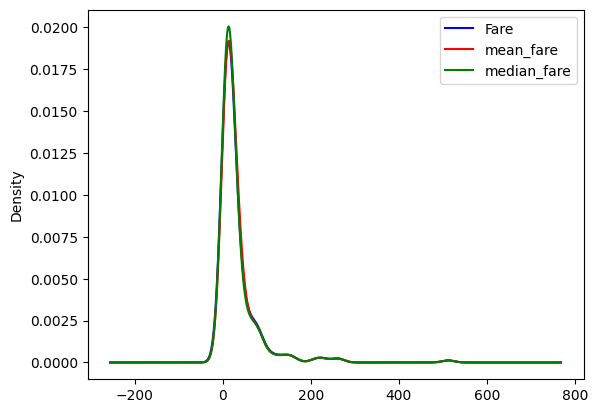

In [76]:
fig =plt.figure()
ax = fig.add_subplot(111)

x_train['Fare'].plot(kind='kde',ax=ax,color='blue')

x_train['mean_fare'].plot(kind='kde',ax=ax,color='red')

x_train['median_fare'].plot(kind='kde',ax=ax,color='green') 

lines , labels =ax.get_legend_handles_labels()
ax.legend(lines,labels , loc='best')

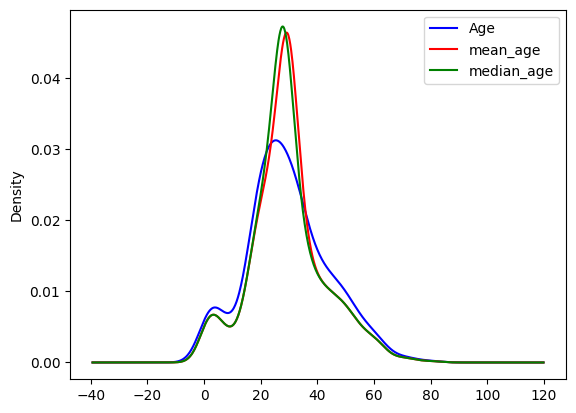

In [77]:
fig =plt.figure()
ax = fig.add_subplot(111)

x_train['Age'].plot(kind='kde',ax=ax,color='blue')

x_train['mean_age'].plot(kind='kde',ax=ax,color='red')

x_train['median_age'].plot(kind='kde',ax=ax,color='green') 

lines , labels =ax.get_legend_handles_labels()
ax.legend(lines,labels , loc='best')

In [78]:
x_train.cov()

,Age,Fare,Family,mean_age,median_age,mean_fare,median_fare
Age,210.251707,75.481375,-6.993325,210.251707,210.251707,71.193767,70.082085
Fare,75.481375,2761.031435,18.599163,60.224654,63.938058,2761.031435,2761.031435
Family,-6.993325,18.599163,2.830892,-5.616299,-5.587710,17.657433,17.672035
mean_age,210.251707,60.224654,-5.616299,168.851934,168.851934,57.175304,56.282518
median_age,210.251707,63.938058,-5.587710,168.851934,169.207310,60.700688,59.728510
mean_fare,71.193767,2761.031435,17.657433,57.175304,60.700688,2621.232375,2621.232375
median_fare,70.082085,2761.031435,17.672035,56.282518,59.728510,2621.232375,2637.012482


In [79]:
x_train.corr()

,Age,Fare,Family,mean_age,median_age,mean_fare,median_fare
Age,1.000000,0.091482,-0.319651,1.000000,1.000000,0.088944,0.087232
Fare,0.091482,1.000000,0.207193,0.088151,0.093496,1.000000,1.000000
Family,-0.319651,0.207193,1.000000,-0.256883,-0.255307,0.204981,0.204536
mean_age,1.000000,0.088151,-0.256883,1.000000,0.998949,0.085941,0.084346
median_age,1.000000,0.093496,-0.255307,0.998949,1.000000,0.091145,0.089416
mean_fare,0.088944,1.000000,0.204981,0.085941,0.091145,1.000000,0.997003
median_fare,0.087232,1.000000,0.204536,0.084346,0.089416,0.997003,1.000000


<Axes: >

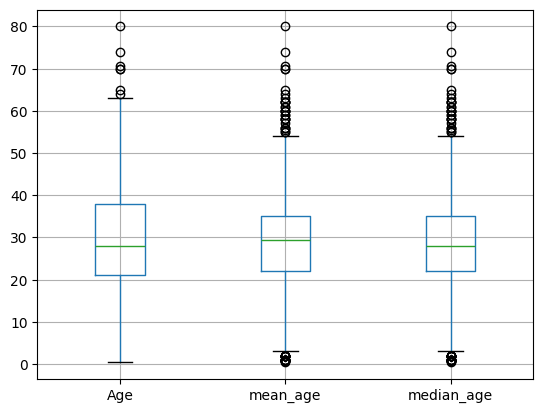

In [80]:
x_train[['Age','mean_age','median_age']].boxplot()

<Axes: >

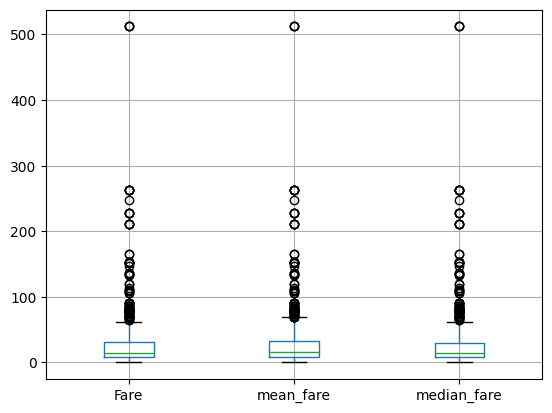

In [81]:
x_train[['Fare','mean_fare','median_fare']].boxplot()

In [89]:
x_train ,x_test ,y_train,y_test = train_test_split(df.drop(columns=['Survived']),df['Survived'],test_size=0.2,random_state=42)

imp1 = SimpleImputer(strategy='median')
imp2 = SimpleImputer(strategy='mean')

In [90]:
trf = ColumnTransformer([
    ('imputer1',imp1,['Age']),
    ('imputer2',imp2,['Fare'])
],remainder='passthrough')

In [91]:
trf.fit(x_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('imputer1', ...), ('imputer2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

In [92]:
trf.named_transformers_['imputer1'].statistics_


array([28.])

In [93]:
trf.named_transformers_['imputer2'].statistics_


array([32.51778772])

In [94]:
x_train = trf.transform(x_train)
x_test = trf.transform(x_test)

In [95]:
x_train

array([[ 45.5       ,  28.5       ,   0.        ],
       [ 23.        ,  13.        ,   0.        ],
       [ 32.        ,   7.925     ,   0.        ],
       ...,
       [ 41.        ,  32.51778772,   2.        ],
       [ 14.        , 120.        ,   3.        ],
       [ 21.        ,  77.2875    ,   1.        ]], shape=(712, 3))

# arbitarry 
replace null value by given number 
main reason is to highlight missing data 

In [96]:
imputer1 = SimpleImputer(strategy='constant',fill_value=99)
imputer2 = SimpleImputer(strategy='constant',fill_value=-1)

# end of distribution  
used to fill null values by outlier 
main reason is to highlight missing data

# handing categorical missing values

In [98]:
h = pd.read_csv('home_train.csv',usecols=['GarageQual','FireplaceQu','SalePrice'])

In [99]:
h.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [103]:
h.isnull().mean()

FireplaceQu    0.472603
GarageQual     0.055479
SalePrice      0.000000
dtype: float64

In [104]:
h['GarageQual'].mode()

0    TA
Name: GarageQual, dtype: object

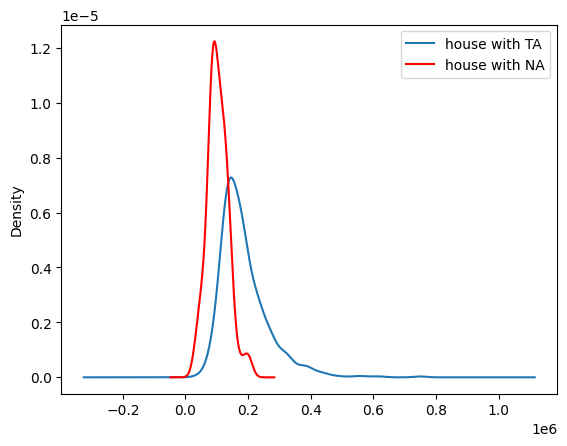

In [106]:
fig = plt.figure()
ax = fig.add_subplot(111)

h[h['GarageQual']=='TA']['SalePrice'].plot(kind='kde',ax=ax)

h[h['GarageQual'].isnull()]['SalePrice'].plot(kind='kde',ax = ax , color='red')

lines , labels = ax.get_legend_handles_labels()
labels = ['house with TA','house with NA']
ax.legend(lines, labels,loc='best')

In [107]:
temp = h[h['GarageQual']=='TA']['SalePrice']

In [108]:
h['GarageQual'].fillna('TA',inplace=True)
# missing in place ofTA to create diff category name of missing 

C:\Users\bhard\AppData\Local\Temp\ipykernel_32368\1470169774.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  h['GarageQual'].fillna('TA',inplace=True)


<Axes: xlabel='GarageQual'>

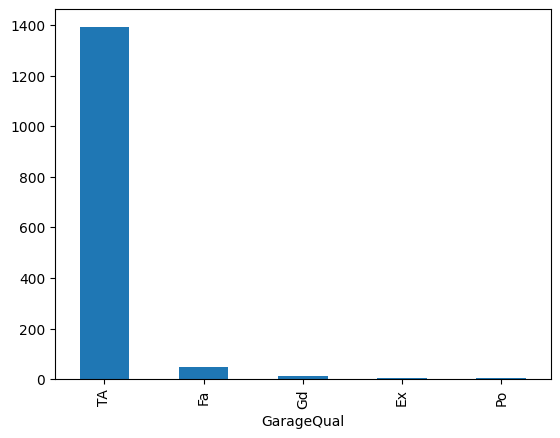

In [109]:
h['GarageQual'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'GarageQual')

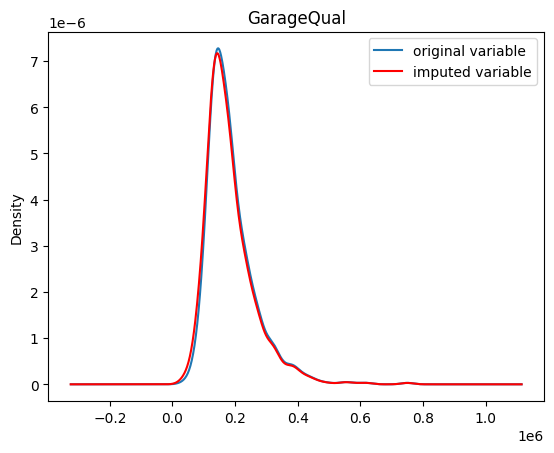

In [111]:
fig = plt.figure()
ax = fig.add_subplot(111)


temp.plot(kind='kde',ax=ax)

h[h['GarageQual']=='TA']['SalePrice'].plot(kind='kde',ax=ax ,color='red')

lines , labels = ax.get_legend_handles_labels()
labels = ['original variable','imputed variable']
ax.legend(lines, labels,loc='best')

plt.title('GarageQual')

# same steps for all categorical columns which has missingvalues

In [112]:
from sklearn.impute import SimpleImputer


In [113]:
x_train,x_test,y_train,y_test = train_test_split(h.drop(columns=['SalePrice']),h['SalePrice'],test_size=0.2,random_state=42)

In [114]:
impute = SimpleImputer(strategy='most_frequent') 
# for missing missing strategy='constant',fill_value = 'missing'

In [115]:
x_train = impute.fit_transform(x_train)
x_test = impute.transform(x_test)

In [116]:
impute.statistics_

array(['Gd', 'TA'], dtype=object)